# Regression Model Validation

This notebook is used to train and evaluate the regression model to predict fire numbers based on temperature data.

## 1. Import Necessary Libraries and Data Path

In [13]:
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import os

notebook_dir = os.path.abspath('')
project_root = os.path.dirname(os.path.dirname(notebook_dir))

import data_processor
data_processor.DATA_PATH = os.path.join(project_root, 'data', 'processed')

## 2. Data Preparation

In [14]:
print("\nPreparing data...")
merged_data, temp_cols = data_processor.prepare_weather_fire_data(
    data_type='count', 
    weather_types=['temp'] 
)


Preparing data...

Data shape after merging:
Data shape: (1625, 30)
Data type selected: ['temp']


## 3. Split Dataset

In [15]:
from data_processor import split_dataset

print("\nBegin spliting data...")
(X_train, y_train), (X_val, y_val), (X_test, y_test) = data_processor.split_dataset(
    merged_data=merged_data,
    feature_columns=temp_cols,
    target_column='fire_count'
)


Begin spliting data...
Data set splited successfully:
Training set size: 975 (60.00%)
Validating set size: 325 (20.00%)
Testing set size: 325 (20.00%)


## 4. Pre-process Features

In [16]:
from data_processor import preprocess_features

print("\nPre-processing features...")
X_train_processed, X_val_processed, X_test_processed = preprocess_features(X_train, X_val, X_test)



Pre-processing features...

Data pre-processing results:
Training set shape: (975, 29)
Validating set shape: (325, 29)
Testing set shape: (325, 29)

Check missing-values in the pre-processed data:
Missing value of training set: 0
Missing value of validating set: 0
Missing value of testing set: 0


In [17]:

def plot_trends(merged_data, y_pred, model_name, temp_cols, val_indices):
    val_data = merged_data.loc[val_indices]
    
    predictions_df = pd.DataFrame({
        'Actual': val_data['fire_count'],
        'Predicted': y_pred
    }, index=val_data.index)
    
    avg_temp = val_data[temp_cols].mean(axis=1)
    
    plt.figure(figsize=(12, 6))
    plt.scatter(avg_temp, predictions_df['Actual'], 
               alpha=0.5, label='Actual Data')
    plt.scatter(avg_temp, predictions_df['Predicted'], 
               alpha=0.5, label='Predicted Data')
    
    z1 = np.polyfit(avg_temp, predictions_df['Actual'], 1)
    p1 = np.poly1d(z1)
    plt.plot(avg_temp, p1(avg_temp), "r--", alpha=0.8, label='Actual Trend')
    
    z2 = np.polyfit(avg_temp, predictions_df['Predicted'], 1)
    p2 = np.poly1d(z2)
    plt.plot(avg_temp, p2(avg_temp), "g--", alpha=0.8, label='Predicted Trend')
    
    plt.title(f'{model_name} - Average Temperature vs Fire Count')
    plt.xlabel('Average Temperature')
    plt.ylabel('Fire Count')
    plt.legend()
    plt.grid(True, linestyle='--', alpha=0.3)
    plt.tight_layout()
    plt.show()

def train_and_evaluate_models(X_train, X_val, y_train, y_val, merged_data, temp_cols):
    global linear_importance, feature_importance
    models = {
        'Linear Regression': LinearRegression(),
        'Random Forest': RandomForestRegressor(
            n_estimators=100,  
            max_depth=10,      
            random_state=42
        )
    }
    
    results = {}
    
    for name, model in models.items():
        print(f"\nTraining {name}...")
        model.fit(X_train, y_train)
        
        y_pred = model.predict(X_val)
        
        mse = mean_squared_error(y_val, y_pred)
        rmse = np.sqrt(mse)
        r2 = r2_score(y_val, y_pred)
        
        print(f"{name} Evaluation Results:")
        print(f"Mean Squared Error (MSE): {mse:.4f}")
        print(f"Root Mean Squared Error (RMSE): {rmse:.4f}")
        print(f"R-squared (R²): {r2:.4f}")
        
        plt.figure(figsize=(10, 6))
        plt.scatter(y_val, y_pred, alpha=0.5)
        plt.plot([y_val.min(), y_val.max()], [y_val.min(), y_val.max()], 'r--', lw=2)
        plt.title(f'{name} - Actual vs Predicted')
        plt.xlabel('Actual Fire Count')
        plt.ylabel('Predicted Fire Count')
        plt.grid(True, linestyle='--', alpha=0.7)
        plt.tight_layout()
        plt.show()

        plot_trends(merged_data, y_pred, name, temp_cols, X_val.index)
        if name == 'Random Forest':
            # Random Forest feature importance
            feature_importance = pd.Series(
                model.feature_importances_,
                index=X_train.columns
            ).sort_values(ascending=True)
            
            plt.figure(figsize=(12, 8))
            feature_importance.plot(kind='barh')
            plt.title('Random Forest - Feature Importance')
            plt.xlabel('Importance Score')
            plt.ylabel('Weather Stations')
            plt.grid(True, linestyle='--', alpha=0.3)
            plt.tight_layout()
            plt.show()
        
        if name == 'Linear Regression':
            # Linear Regression feature importance (absolute coefficients)
            linear_importance = pd.Series(
                np.abs(model.coef_),
                index=X_train.columns
            ).sort_values(ascending=True)
            
            plt.figure(figsize=(12, 8))
            linear_importance.plot(kind='barh')
            plt.title('Linear Regression - Feature Importance')
            plt.xlabel('Absolute Coefficient Value')
            plt.ylabel('Weather Stations')
            plt.grid(True, linestyle='--', alpha=0.3)
            plt.tight_layout()
            plt.show()
            
        results[name] = {
            'model': model,
            'mse': mse,
            'rmse': rmse,
            'r2': r2,
            'predictions': y_pred
        }
    
        if name == 'Random Forest':
            print("\nRandom Forest - Top 10 Most Important Features:")
            print(feature_importance.tail(10))
        
        if name == 'Linear Regression':
            print("\nLinear Regression - Top 10 Most Important Features:")
            print(linear_importance.tail(10))
    
    # Compare model performances
    print("\nModel Performance Comparison:")
    performance_comparison = pd.DataFrame({
        'MSE': [results[model]['mse'] for model in models],
        'RMSE': [results[model]['rmse'] for model in models],
        'R²': [results[model]['r2'] for model in models]
    }, index=models.keys())
    print(performance_comparison)
    
    return results



## 6. Execute Model Training and Evaluation


Starting model training and evaluation...

Training Linear Regression...
Linear Regression Evaluation Results:
Mean Squared Error (MSE): 149.0048
Root Mean Squared Error (RMSE): 12.2068
R-squared (R²): 0.1607


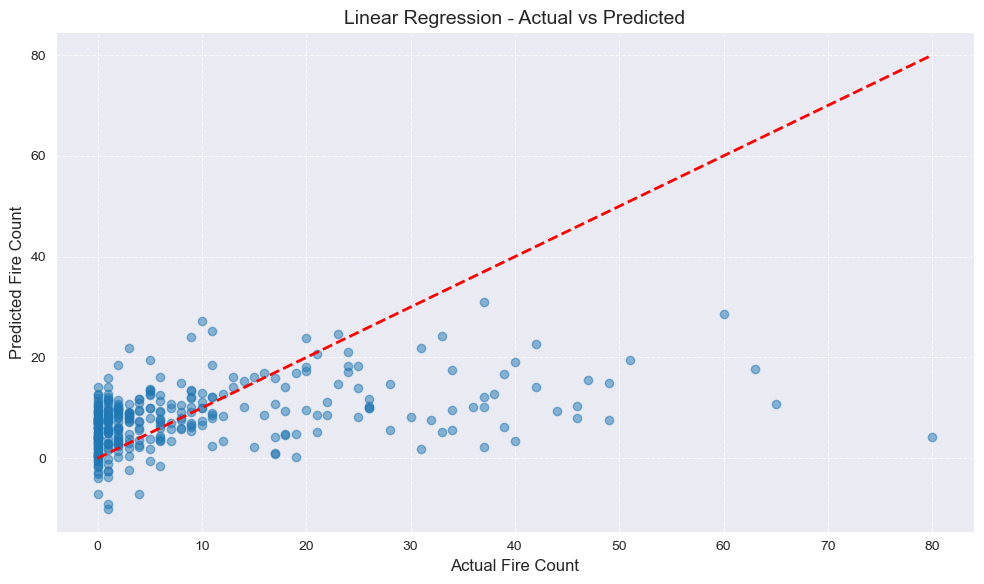

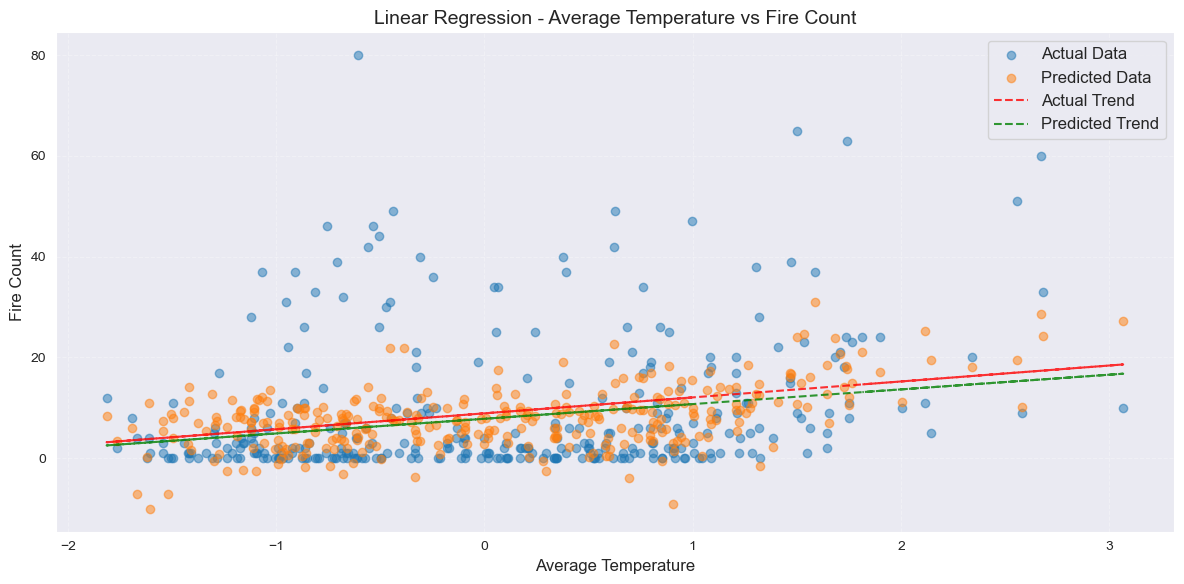

C:\Users\18400\AppData\Local\Temp\ipykernel_21024\2920168939.py:101: UserWarning: Glyph 34451 (\N{CJK UNIFIED IDEOGRAPH-8693}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\18400\miniconda3\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 34451 (\N{CJK UNIFIED IDEOGRAPH-8693}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


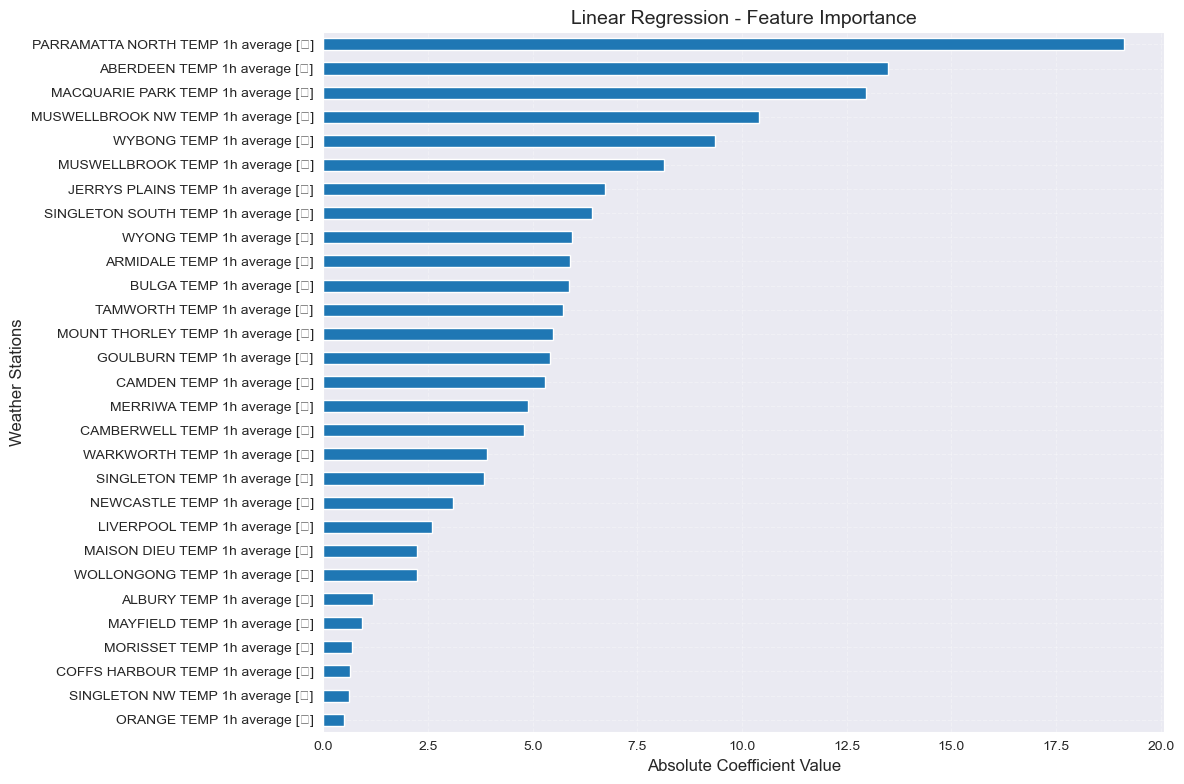


Linear Regression - Top 10 Most Important Features:
ARMIDALE TEMP 1h average [蚓]             5.889386
WYONG TEMP 1h average [蚓]                5.935010
SINGLETON SOUTH TEMP 1h average [蚓]      6.414436
JERRYS PLAINS TEMP 1h average [蚓]        6.716766
MUSWELLBROOK TEMP 1h average [蚓]         8.140029
WYBONG TEMP 1h average [蚓]               9.364053
MUSWELLBROOK NW TEMP 1h average [蚓]     10.407126
MACQUARIE PARK TEMP 1h average [蚓]      12.957263
ABERDEEN TEMP 1h average [蚓]            13.481905
PARRAMATTA NORTH TEMP 1h average [蚓]    19.122291
dtype: float64

Training Random Forest...
Random Forest Evaluation Results:
Mean Squared Error (MSE): 139.3679
Root Mean Squared Error (RMSE): 11.8054
R-squared (R²): 0.2150


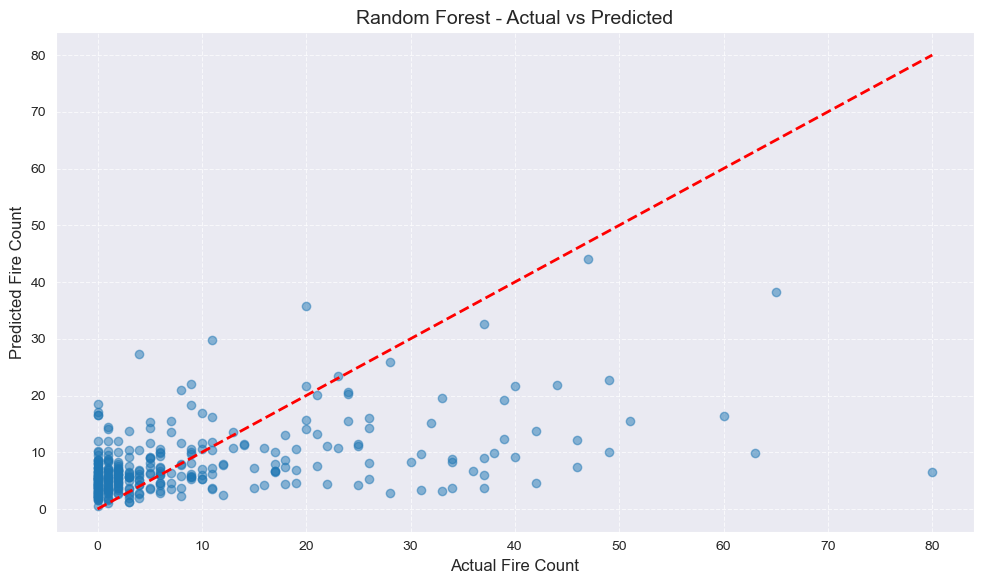

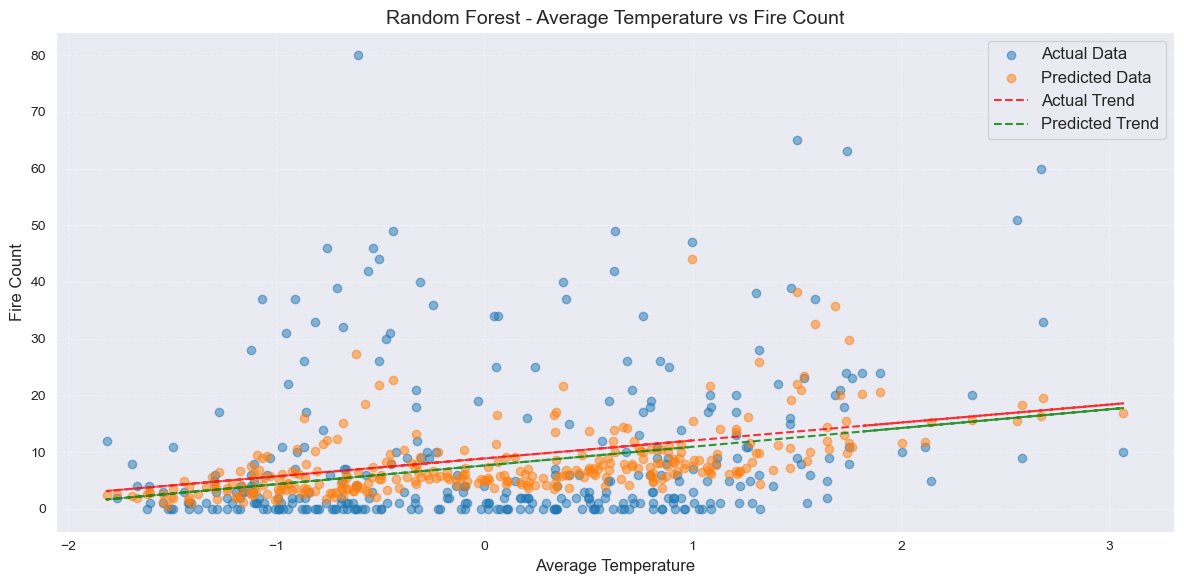

C:\Users\18400\AppData\Local\Temp\ipykernel_21024\2920168939.py:85: UserWarning: Glyph 34451 (\N{CJK UNIFIED IDEOGRAPH-8693}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\18400\miniconda3\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 34451 (\N{CJK UNIFIED IDEOGRAPH-8693}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


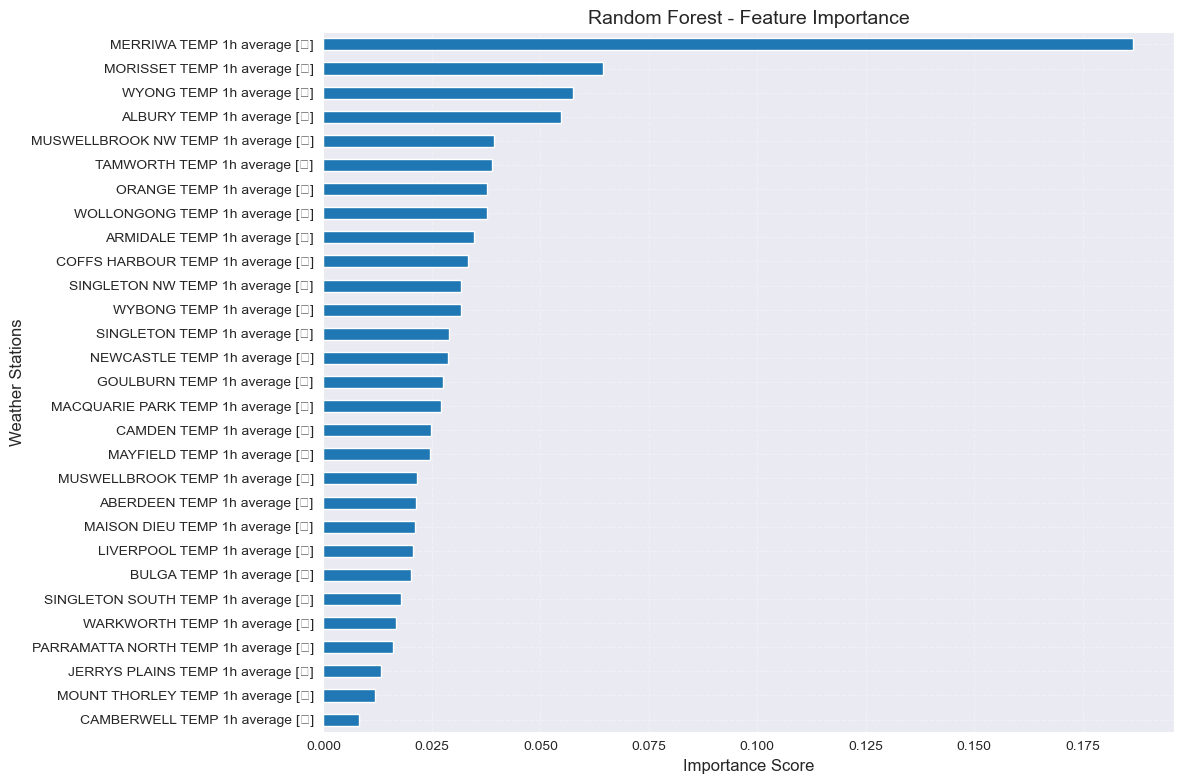


Random Forest - Top 10 Most Important Features:
COFFS HARBOUR TEMP 1h average [蚓]      0.033430
ARMIDALE TEMP 1h average [蚓]           0.034806
WOLLONGONG TEMP 1h average [蚓]         0.037748
ORANGE TEMP 1h average [蚓]             0.037770
TAMWORTH TEMP 1h average [蚓]           0.038783
MUSWELLBROOK NW TEMP 1h average [蚓]    0.039326
ALBURY TEMP 1h average [蚓]             0.054835
WYONG TEMP 1h average [蚓]              0.057643
MORISSET TEMP 1h average [蚓]           0.064346
MERRIWA TEMP 1h average [蚓]            0.186725
dtype: float64

Model Performance Comparison:
                          MSE       RMSE        R²
Linear Regression  149.004759  12.206751  0.160682
Random Forest      139.367864  11.805417  0.214965


C:\Users\18400\AppData\Local\Temp\ipykernel_21024\651279783.py:29: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(model_names, rotation=45)
C:\Users\18400\AppData\Local\Temp\ipykernel_21024\651279783.py:29: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(model_names, rotation=45)
C:\Users\18400\AppData\Local\Temp\ipykernel_21024\651279783.py:29: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(model_names, rotation=45)


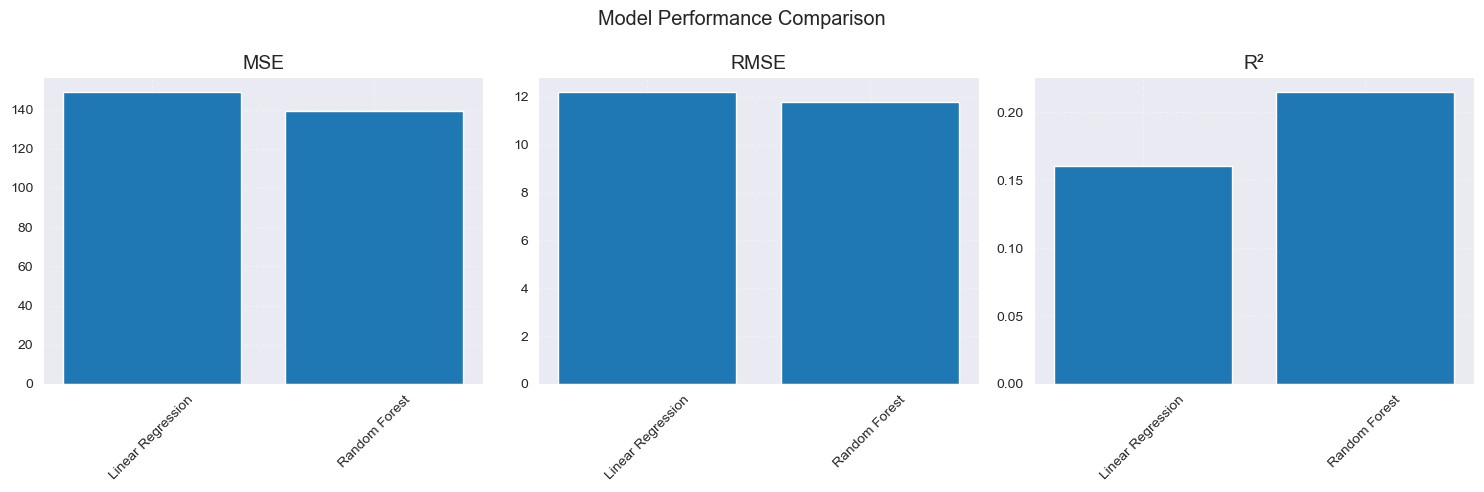

In [18]:

plt.rcParams['font.size'] = 12
plt.rcParams['axes.labelsize'] = 12
plt.rcParams['axes.titlesize'] = 14
plt.rcParams['xtick.labelsize'] = 10
plt.rcParams['ytick.labelsize'] = 10

print("\nStarting model training and evaluation...")
model_results = train_and_evaluate_models(X_train_processed, X_val_processed, y_train, y_val, merged_data, temp_cols)

metrics = ['MSE', 'RMSE', 'R²']
model_names = list(model_results.keys())
performance_data = []

for metric in metrics:
    if metric == 'MSE':
        values = [results['mse'] for results in model_results.values()]
    elif metric == 'RMSE':
        values = [results['rmse'] for results in model_results.values()]
    else:  # R²
        values = [results['r2'] for results in model_results.values()]
    performance_data.append(values)

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
fig.suptitle('Model Performance Comparison')

for i, (metric, ax) in enumerate(zip(metrics, axes)):
    ax.bar(model_names, performance_data[i])
    ax.set_title(metric)
    ax.set_xticklabels(model_names, rotation=45)
    ax.grid(True, linestyle='--', alpha=0.3)

plt.tight_layout()
plt.show()